# GPUs and CUDA

This notebook needs an NVIDIA graphics card. Locally, install the extra dependencies with `uv sync --group gpu`. Without one, use Google Colab: *File → Upload notebook*, then *Runtime → Change runtime type → T4 GPU*. The notebook does not use any other file of this project, so it runs there on its own.

## Environment

In Colab, PyTorch and CuPy (a NumPy-like library for GPUs) are usually preinstalled; this cell installs CuPy if it is missing. Locally, it does nothing.

In [ ]:
import importlib.util
import subprocess
import sys

running_in_colab = "google.colab" in sys.modules
if running_in_colab and importlib.util.find_spec("cupy") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "cupy-cuda12x"], check=True)

In [ ]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("No NVIDIA GPU found. Run this notebook in Google Colab with a GPU runtime.")

torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 5060 Ti'

## From graphics to AI

A **GPU** (*graphics processing unit*, the chip on a graphics card) was designed to draw images for games. Drawing a frame means computing the colour of millions of pixels, and each pixel can be computed independently of the others with the same small program. So GPUs were built to do **one simple thing on huge amounts of data at the same time**.

Around 2010, researchers noticed that neural networks have the same shape of work: the same operations, mostly matrix multiplications (notebook 02), applied to huge arrays of numbers. In 2012 a network called **AlexNet**, trained on two ordinary gaming GPUs, won the most important image-recognition competition by a wide margin. That result started the deep-learning boom, and since then AI and GPUs have grown together.

## CPU versus GPU

Think of two kitchens:

- The **CPU** is a small team of expert chefs (its cores, notebook 04). Each can prepare any complicated dish and react to surprises. It is designed to finish *each* task as fast as possible.
- The **GPU** is a factory kitchen with thousands of line cooks. Each is slower and can only follow simple instructions, and they work in groups doing the same step at the same time. But for a job like "chop ten thousand onions", nothing beats them. It is designed to finish *the largest amount* of work per second.

A matrix multiplication is exactly that kind of job: each of the $n \times n$ results is an independent dot product that could be computed by a different cook.

## CUDA: C for GPUs

**CUDA** is NVIDIA's platform for using its GPUs for general computation, not only graphics. Its programming language is an extension of C and C++: you write a function in almost ordinary C, called a **kernel**, and the GPU runs it on thousands of **threads** at the same time. A thread is one independent worker running the kernel's code on its own piece of the data.

Compare the matrix multiplication of notebook 03 in C with the same computation as a CUDA kernel:

```c
// C on the CPU: one worker goes through every row and every column
for (size_t i = 0; i < n; i++) {
    for (size_t j = 0; j < n; j++) {
        double sum = 0.0;
        for (size_t k = 0; k < n; k++) {
            sum += a[i * n + k] * b[k * n + j];
        }
        c[i * n + j] = sum;
    }
}
```

```c
// CUDA on the GPU: every thread computes ONE result
__global__ void matmul_naive(const float *a, const float *b, float *c, int n) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int column = blockIdx.x * blockDim.x + threadIdx.x;
    if (row < n && column < n) {
        float sum = 0.0f;
        for (int k = 0; k < n; k++) {
            sum += a[row * n + k] * b[k * n + column];
        }
        c[row * n + column] = sum;
    }
}
```

The inner part is the same C. What changed is that the two outer loops have disappeared. Instead of one worker going through all the rows and columns, the GPU starts one thread per result, and each thread works out *which* row and column it is responsible for from its position (`blockIdx` and `threadIdx`, explained below). For $n = 4096$ that is almost 17 million threads, and the GPU runs thousands of them at the same time.

## Running the kernel

**CuPy** can compile a CUDA kernel written as text and run it from Python. The kernel uses `float`, 32-bit decimal numbers, because GPUs are much faster with them than with the 64-bit numbers used so far.

In [ ]:
import cupy as cp

naive_kernel_source = r"""
extern "C" __global__
void matmul_naive(const float *a, const float *b, float *c, int n) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int column = blockIdx.x * blockDim.x + threadIdx.x;
    if (row < n && column < n) {
        float sum = 0.0f;
        for (int k = 0; k < n; k++) {
            sum += a[row * n + k] * b[k * n + column];
        }
        c[row * n + column] = sum;
    }
}
"""
matmul_naive_kernel = cp.RawKernel(naive_kernel_source, "matmul_naive")

Threads are organised in **blocks**; here each block is a 16 × 16 square of threads, responsible for a 16 × 16 square of the result. To launch the kernel we say how many blocks are needed to cover the whole matrix. Inside the kernel, `blockIdx` tells a thread which block it belongs to, and `threadIdx` its position inside the block: together they give its row and column.

In [ ]:
import math

import numpy as np

THREADS_PER_BLOCK_SIDE = 16

def matmul_naive_cuda(matrix_a: cp.ndarray, matrix_b: cp.ndarray) -> cp.ndarray:
    size = matrix_a.shape[0]
    result = cp.empty((size, size), dtype=cp.float32)
    blocks_per_side = math.ceil(size / THREADS_PER_BLOCK_SIDE)
    matmul_naive_kernel((blocks_per_side, blocks_per_side), (THREADS_PER_BLOCK_SIDE, THREADS_PER_BLOCK_SIDE),
                        (matrix_a, matrix_b, result, np.int32(size)))
    return result

The GPU has **its own memory**, separate from the computer's main memory, so the matrices must first be copied to it (`cp.asarray`), and the result copied back (`cp.asnumpy`). As always, we check the result against NumPy on the CPU, with a slightly larger tolerance because 32-bit numbers keep fewer digits:

In [ ]:
random_generator = np.random.default_rng(42)
host_a = random_generator.standard_normal((512, 512)).astype(np.float32)
host_b = random_generator.standard_normal((512, 512)).astype(np.float32)

gpu_result = matmul_naive_cuda(cp.asarray(host_a), cp.asarray(host_b))
np.allclose(cp.asnumpy(gpu_result), host_a @ host_b, rtol=1e-3, atol=1e-3)

True

## How fast is it?

We now use large 4096 × 4096 matrices. One detail about timing: when Python asks the GPU to do something, the call returns immediately, while the GPU keeps working in the background. So the timing helper below waits for the GPU to finish (`synchronize`) before stopping the clock. At this scale, speed is measured in **TFLOPS**: trillions of operations per second, that is, thousands of GFLOPS.

In [ ]:
import statistics
import time
from collections.abc import Callable

def time_gpu(function: Callable[[], object], repeats: int = 10) -> float:
    function()
    torch.cuda.synchronize()
    measured_seconds = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        torch.cuda.synchronize()
        measured_seconds.append(time.perf_counter() - start)
    return statistics.median(measured_seconds)

def tflops(n: int, seconds: float) -> float:
    return 2 * n**3 / seconds / 1e12

In [ ]:
n = 4096
host_a = random_generator.standard_normal((n, n)).astype(np.float32)
host_b = random_generator.standard_normal((n, n)).astype(np.float32)
device_a, device_b = cp.asarray(host_a), cp.asarray(host_b)

naive_seconds = time_gpu(lambda: matmul_naive_cuda(device_a, device_b))
f"naive CUDA kernel: {naive_seconds * 1000:.0f} ms, {tflops(n, naive_seconds):.2f} TFLOPS"

'naive CUDA kernel: 90 ms, 1.53 TFLOPS'

For comparison, the CPU on the same matrices, with NumPy (BLAS, all cores):

In [ ]:
cpu_measured_seconds = []
for _ in range(3):
    start = time.perf_counter()
    host_a @ host_b
    cpu_measured_seconds.append(time.perf_counter() - start)
cpu_seconds = statistics.median(cpu_measured_seconds)
f"NumPy on the CPU: {cpu_seconds * 1000:.0f} ms, {tflops(n, cpu_seconds):.2f} TFLOPS"

'NumPy on the CPU: 77 ms, 1.79 TFLOPS'

Our simple kernel, a dozen lines of C, is in the same league as NumPy's expert-tuned library running on every core of the CPU. But notebook 04 taught us that simple code is not the end of the story.

## Libraries again: cuBLAS

Just as NumPy calls BLAS on the CPU, the GPU has its own expert-tuned library, **cuBLAS**, written by NVIDIA. PyTorch calls it whenever we multiply two tensors that live on the GPU. In PyTorch, `.to("cuda")` copies a tensor to the GPU (notebook 02 explained that a PyTorch tensor can live in the GPU's memory):

In [ ]:
torch.set_float32_matmul_precision("highest")
torch_a = torch.from_numpy(host_a).to("cuda")
torch_b = torch.from_numpy(host_b).to("cuda")

cublas_seconds = time_gpu(lambda: torch_a @ torch_b)
f"cuBLAS: {cublas_seconds * 1000:.1f} ms, {tflops(n, cublas_seconds):.1f} TFLOPS"

'cuBLAS: 8.1 ms, 17.1 TFLOPS'

In [ ]:
torch.allclose((torch_a @ torch_b).cpu(), torch.from_numpy(host_a @ host_b), rtol=1e-3, atol=1e-3)

True

AI models go one step further: they tolerate numbers with less precision, and recent NVIDIA GPUs contain special circuits, called **tensor cores**, that multiply small matrices of 16-bit numbers extremely fast. Converting the matrices to 16 bits (`half()`) lets cuBLAS use them:

In [ ]:
half_a, half_b = torch_a.half(), torch_b.half()
half_precision_seconds = time_gpu(lambda: half_a @ half_b)
f"cuBLAS with 16-bit numbers: {tflops(n, half_precision_seconds):.1f} TFLOPS"

'cuBLAS with 16-bit numbers: 49.2 TFLOPS'

→ Deep dive: [GPU performance](deep-dives/gpu_performance.ipynb) looks at timing pitfalls, the cost of copying data, the precision formats and their errors, and Triton, a way to write GPU kernels in Python.

## The complete picture

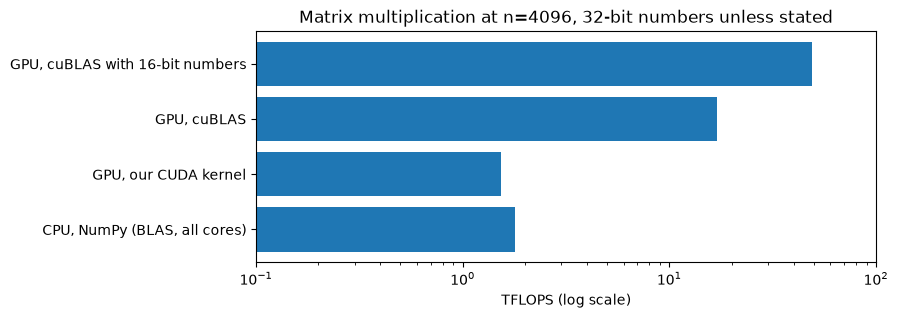

In [ ]:
import matplotlib.pyplot as plt

speed_in_tflops = {
    "CPU, NumPy (BLAS, all cores)": tflops(n, cpu_seconds),
    "GPU, our CUDA kernel": tflops(n, naive_seconds),
    "GPU, cuBLAS": tflops(n, cublas_seconds),
    "GPU, cuBLAS with 16-bit numbers": tflops(n, half_precision_seconds),
}

figure, axis = plt.subplots(figsize=(8, 3))
axis.barh(list(speed_in_tflops), list(speed_in_tflops.values()))
axis.set_xscale("log")
axis.set_xlim(0.1, 100)
axis.set_xlabel("TFLOPS (log scale)")
axis.set_title(f"Matrix multiplication at n={n}, 32-bit numbers unless stated")
plt.show()

The GPU with its own library is an order of magnitude faster than the CPU, and lower precision multiplies that again. This is what made modern AI possible: training a large model takes an enormous number of matrix multiplications, and only this kind of hardware makes that affordable.

Notice also what Python did in this notebook: it never multiplied a single number. It asked CuPy to launch a CUDA kernel, and asked PyTorch to call cuBLAS. It is the same pattern as notebook 04, one level further down: **Python describes the work, and compiled code running on specialised hardware does it.**

## Key ideas

- A **GPU** has thousands of simple cores that work in parallel, ideal for the independent dot products of a matrix multiplication. That is why GPUs drove the rise of deep learning.
- **CUDA** is NVIDIA's platform; its language is essentially C in which a function (a **kernel**) runs on thousands of **threads** at once, each computing its own piece of the result.
- As on the CPU, an expert library (**cuBLAS**) is far faster than simple code, and lower-precision numbers on **tensor cores** are faster still.
- Python drives all of it through libraries such as PyTorch and CuPy, without doing the computation itself.